In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


orders = pd.read_csv('../data/cleaned/olist_orders_dataset.csv')
order_items = pd.read_csv('../data/cleaned/olist_order_items_dataset.csv')
products = pd.read_csv('../data/cleaned/olist_products_dataset.csv')
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['purchaseMonth'] = orders['order_purchase_timestamp'].dt.to_period('M')

# 04-1: monthly sales trend
deliveredOrders = orders[orders['order_status'] == 'delivered']
deliveredItems = order_items[order_items['order_id'].isin(deliveredOrders['order_id'])]
deliveredOrderDetails = deliveredOrders.merge(deliveredItems, on='order_id', how='left')
salesOverTime = deliveredOrderDetails.groupby('purchaseMonth')['item_total_value'].sum()

# 04-2: category revenue (for the Pareto chart)
orderItemsWithCategory = order_items.merge(products, on='product_id', how='left')
productCategoriesGrossRev = orderItemsWithCategory.groupby('product_category_name')['item_total_value'].sum().sort_values(ascending=False)

In [2]:
rfmCrosstab = pd.read_csv('../data/summary/rfm_crosstab.csv', index_col=0)
sellerRev = pd.read_csv('../data/summary/seller_revenue.csv', index_col=0).squeeze()
sameStateSummary = pd.read_csv('../data/summary/same_state_delivery.csv', index_col=0)
monthlyLateRate = pd.read_csv('../data/summary/monthly_late_rate.csv', index_col=0).squeeze()
repeatRateByFirstStatus = pd.read_csv('../data/summary/repeat_rate_by_first_status.csv', index_col=0).squeeze()
sellerScorecard = pd.read_csv('../data/summary/seller_scorecard.csv', index_col=0)

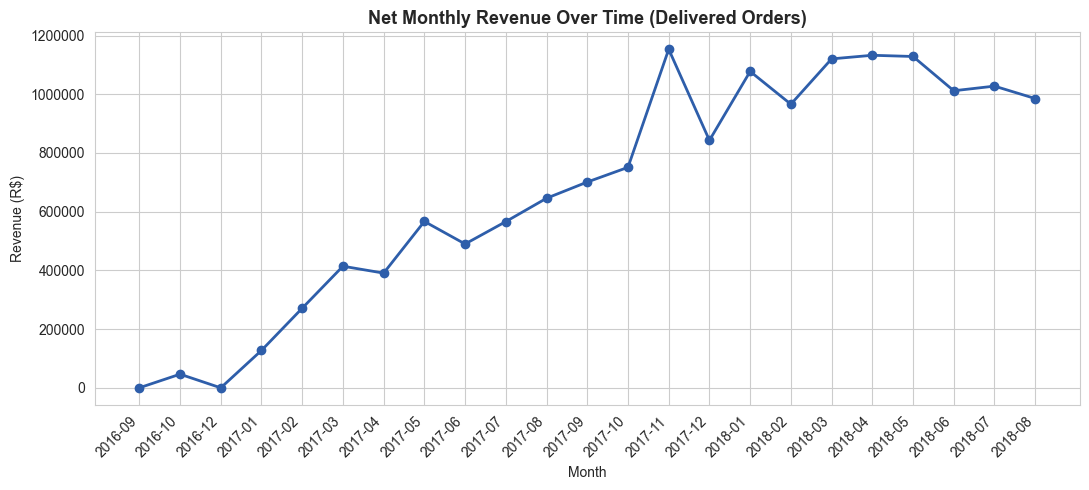

In [4]:

sns.set_style('whitegrid')

fig, ax = plt.subplots(figsize=(11, 5))
salesOverTime.index = salesOverTime.index.astype(str)
ax.plot(salesOverTime.index, salesOverTime.values, marker='o', color='#2E5EAA', linewidth=2)

ax.set_title('Net Monthly Revenue Over Time (Delivered Orders)', fontsize=13, weight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (R$)')
plt.xticks(rotation=45, ha='right')
ax.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('../outputs/04_monthly_sales_trend.png', dpi=150)
plt.show()

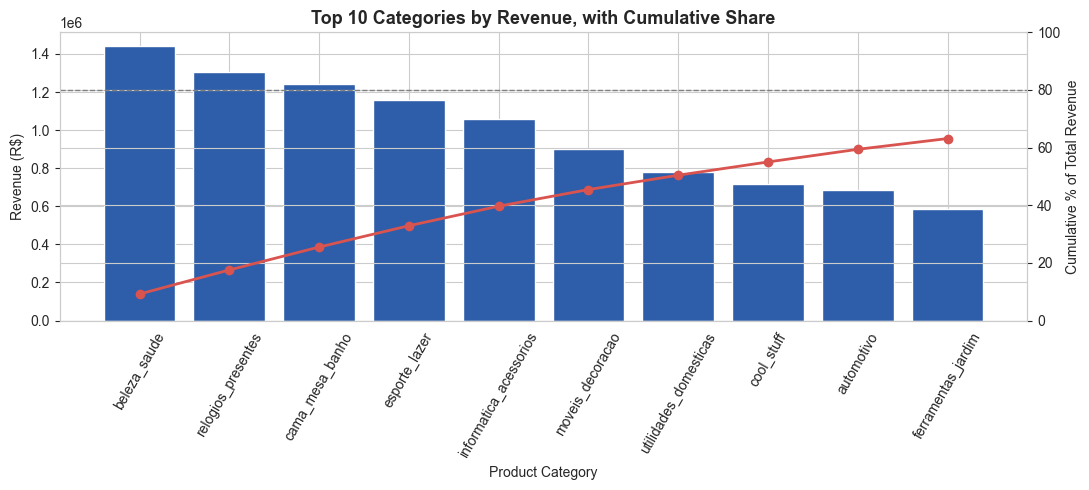

In [5]:
fig, ax1 = plt.subplots(figsize=(11, 5))

top10 = productCategoriesGrossRev.head(10)
cumulativePct = (top10.cumsum() / productCategoriesGrossRev.sum()) * 100

ax1.bar(top10.index, top10.values, color='#2E5EAA')
ax1.set_ylabel('Revenue (R$)')
ax1.set_xlabel('Product Category')
ax1.tick_params(axis='x', rotation=60)

ax2 = ax1.twinx()
ax2.plot(top10.index, cumulativePct.values, color='#D9534F', marker='o', linewidth=2)
ax2.set_ylabel('Cumulative % of Total Revenue')
ax2.set_ylim(0, 100)
ax2.axhline(80, color='gray', linestyle='--', linewidth=1)

plt.title('Top 10 Categories by Revenue, with Cumulative Share', fontsize=13, weight='bold')
plt.tight_layout()
plt.savefig('../outputs/04_category_pareto.png', dpi=150)
plt.show()

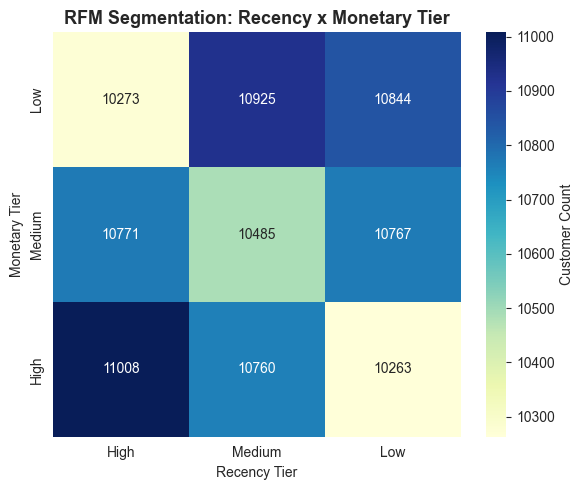

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(rfmCrosstab, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Customer Count'}, ax=ax)

ax.set_title('RFM Segmentation: Recency x Monetary Tier', fontsize=13, weight='bold')
ax.set_xlabel('Recency Tier')
ax.set_ylabel('Monetary Tier')

plt.tight_layout()
#plt.savefig('../outputs/05_rfm_heatmap.png', dpi=150)
plt.show()

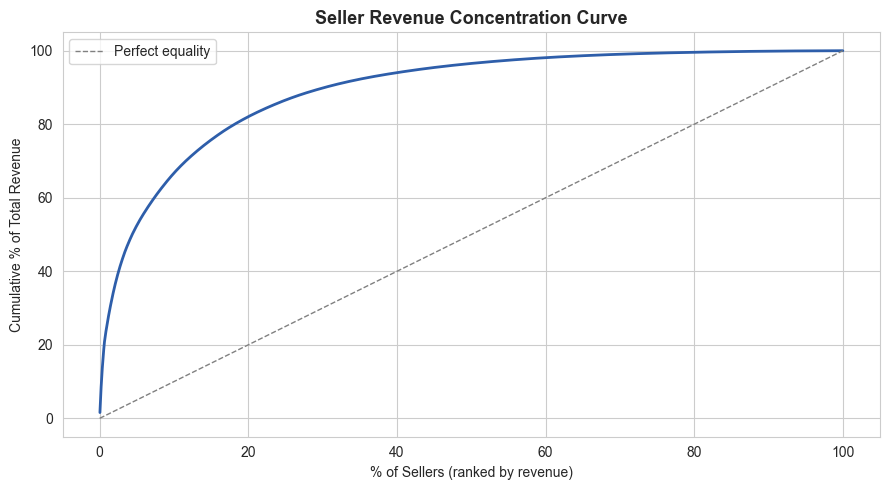

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

sellerRevSorted = sellerRev.sort_values(ascending=False).reset_index(drop=True)
cumulativePct = (sellerRevSorted.cumsum() / sellerRevSorted.sum()) * 100
sellerPct = ((sellerRevSorted.index + 1) / len(sellerRevSorted)) * 100

ax.plot(sellerPct, cumulativePct, color='#2E5EAA', linewidth=2)
ax.plot([0, 100], [0, 100], color='gray', linestyle='--', linewidth=1, label='Perfect equality')

ax.set_title('Seller Revenue Concentration Curve', fontsize=13, weight='bold')
ax.set_xlabel('% of Sellers (ranked by revenue)')
ax.set_ylabel('Cumulative % of Total Revenue')
ax.legend()

plt.tight_layout()
#plt.savefig('../outputs/05_seller_concentration_curve.png', dpi=150)
plt.show()

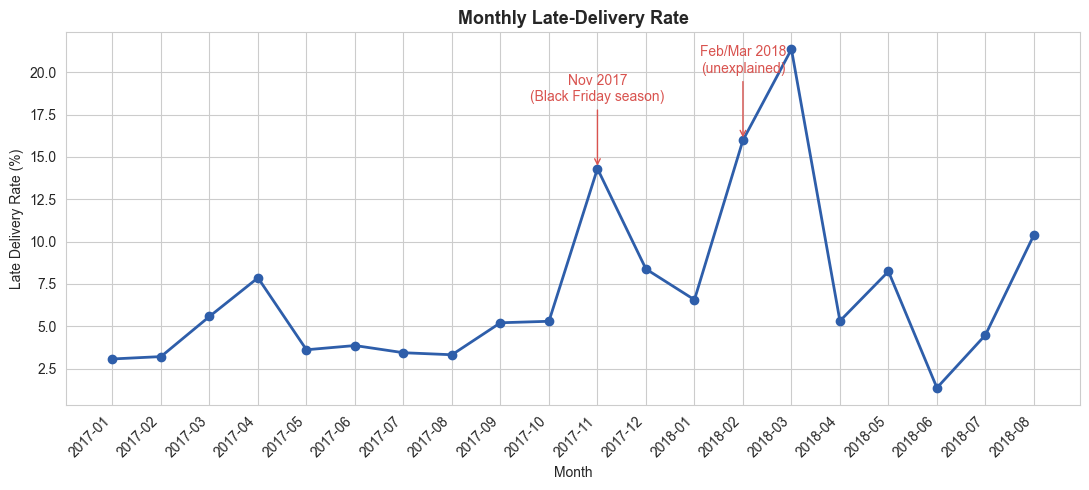

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))

# Trim the near-empty ramp-up/tail-off months before plotting - same
# exclusion used throughout 06 for this exact series.
plotRate = monthlyLateRate[(monthlyLateRate.index >= '2017-01') & (monthlyLateRate.index <= '2018-08')]
plotRate.index = plotRate.index.astype(str)

ax.plot(plotRate.index, plotRate.values, marker='o', color='#2E5EAA', linewidth=2)

# Annotate the two confirmed-genuine spikes
ax.annotate('Nov 2017\n(Black Friday season)', xy=('2017-11', plotRate['2017-11']),
            xytext=('2017-11', plotRate['2017-11'] + 4),
            arrowprops=dict(arrowstyle='->', color='#D9534F'), ha='center', color='#D9534F')
ax.annotate('Feb/Mar 2018\n(unexplained)', xy=('2018-02', plotRate['2018-02']),
            xytext=('2018-02', plotRate['2018-02'] + 4),
            arrowprops=dict(arrowstyle='->', color='#D9534F'), ha='center', color='#D9534F')

ax.set_title('Monthly Late-Delivery Rate', fontsize=13, weight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Late Delivery Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../outputs/06_late_rate_trend.png', dpi=150)
plt.show()

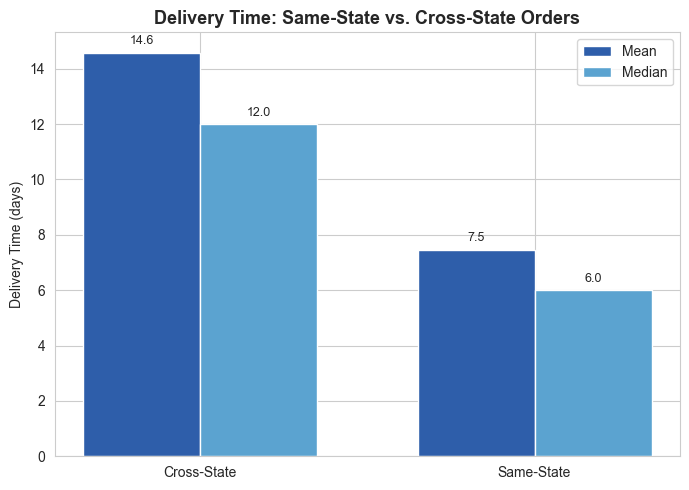

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

labels = ['Cross-State', 'Same-State']
means = [sameStateSummary.loc[False, 'meanDeliveryDays'], sameStateSummary.loc[True, 'meanDeliveryDays']]
medians = [sameStateSummary.loc[False, 'medianDeliveryDays'], sameStateSummary.loc[True, 'medianDeliveryDays']]

x = range(len(labels))
width = 0.35

ax.bar([i - width/2 for i in x], means, width, label='Mean', color='#2E5EAA')
ax.bar([i + width/2 for i in x], medians, width, label='Median', color='#5BA3D0')

ax.set_xticks(list(x))
ax.set_xticklabels(labels)
ax.set_ylabel('Delivery Time (days)')
ax.set_title('Delivery Time: Same-State vs. Cross-State Orders', fontsize=13, weight='bold')
ax.legend()

for i, (m, md) in enumerate(zip(means, medians)):
    ax.text(i - width/2, m + 0.3, f'{m:.1f}', ha='center', fontsize=9)
    ax.text(i + width/2, md + 0.3, f'{md:.1f}', ha='center', fontsize=9)

plt.tight_layout()
#plt.savefig('../outputs/06_same_state_delivery.png', dpi=150)
plt.show()

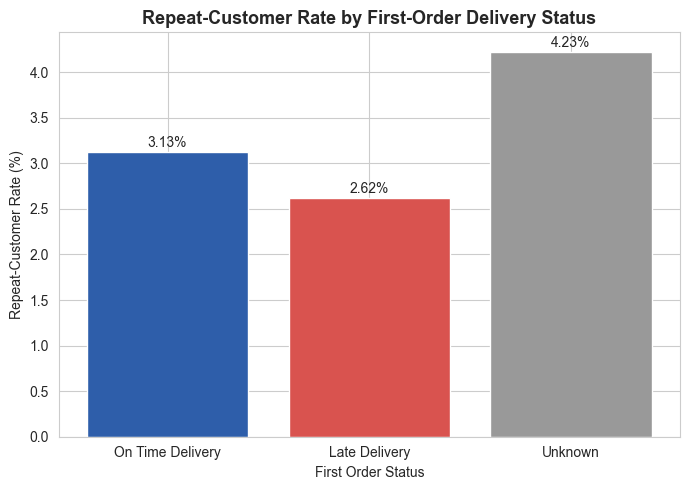

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))

order = ['On Time Delivery', 'Late Delivery', 'Unknown']
plotData = repeatRateByFirstStatus.reindex(order)

colors = ['#2E5EAA', '#D9534F', '#999999']
bars = ax.bar(plotData.index, plotData.values, color=colors)

ax.set_title('Repeat-Customer Rate by First-Order Delivery Status', fontsize=13, weight='bold')
ax.set_xlabel('First Order Status')
ax.set_ylabel('Repeat-Customer Rate (%)')

for bar, val in zip(bars, plotData.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.05, f'{val:.2f}%', ha='center', fontsize=10)

plt.tight_layout()
#plt.savefig('../outputs/07_repeat_rate_by_status.png', dpi=150)
plt.show()

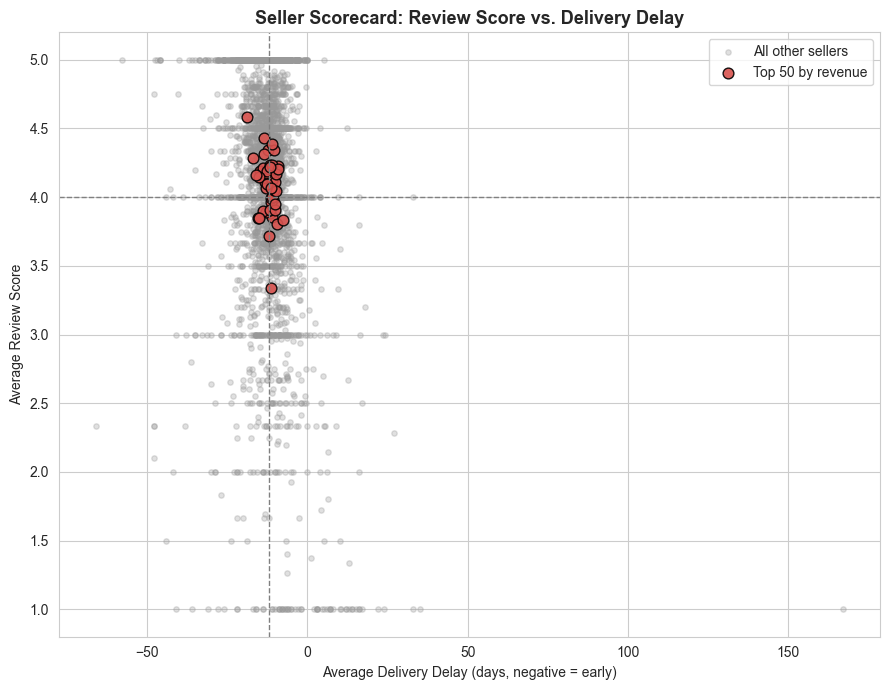

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))

reviewCutoff = 4
delayCutoff = sellerScorecard['avgDelay'].median()

notTop50 = sellerScorecard[~sellerScorecard['highRevenue']]
top50 = sellerScorecard[sellerScorecard['highRevenue']]

ax.scatter(notTop50['avgDelay'], notTop50['avgReviewScore'],
           s=15, alpha=0.3, color='#999999', label='All other sellers')
ax.scatter(top50['avgDelay'], top50['avgReviewScore'],
           s=60, alpha=0.9, color='#D9534F', edgecolor='black', label='Top 50 by revenue')

ax.axhline(reviewCutoff, color='gray', linestyle='--', linewidth=1)
ax.axvline(delayCutoff, color='gray', linestyle='--', linewidth=1)

ax.set_title('Seller Scorecard: Review Score vs. Delivery Delay', fontsize=13, weight='bold')
ax.set_xlabel('Average Delivery Delay (days, negative = early)')
ax.set_ylabel('Average Review Score')
ax.legend()

plt.tight_layout()
#plt.savefig('../outputs/07_seller_scorecard_scatter.png', dpi=150)
plt.show()